## Summer Clothing Sales Prediction

Data source: https://www.kaggle.com/datasets/jmmvutu/summer-products-and-sales-in-ecommerce-wish

### Importing Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split

import tensorflow as tf

pd.set_option('display.max_columns', None)

In [4]:
data = pd.read_csv('archive/summer-products-with-rating-and-performance_2020-08.csv')
data

,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,tags,product_color,product_variation_size_id,product_variation_inventory,shipping_option_name,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,has_urgency_banner,urgency_text,origin_country,merchant_title,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id,theme,crawl_month
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,16.00,14,EUR,100,0,3.76,54,26.0,8.0,10.0,1.0,9.0,0,0,0,0,"Summer,Fashion,womenunderwearsuit,printedpajam...",white,M,50,Livraison standard,4,0,34,50,1.0,Quantité limitée !,CN,zgrdejia,zgrdejia,(568 notes),568,4.128521,595097d6a26f6e070cb878d1,0,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0,summer,2020-08
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,8.00,22,EUR,20000,1,3.45,6135,2269.0,1027.0,1118.0,644.0,1077.0,0,0,0,0,"Mini,womens dresses,Summer,Patchwork,fashion d...",green,XS,50,Livraison standard,2,0,41,50,1.0,Quantité limitée !,CN,SaraHouse,sarahouse,"83 % avis positifs (17,752 notes)",17752,3.899673,56458aa03a698c35c9050988,0,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38,summer,2020-08
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,8.00,43,EUR,100,0,3.57,14,5.0,4.0,2.0,0.0,3.0,0,0,0,0,"Summer,cardigan,women beachwear,chiffon,Sexy w...",leopardprint,XS,1,Livraison standard,3,0,36,50,1.0,Quantité limitée !,CN,hxt520,hxt520,86 % avis positifs (295 notes),295,3.989831,5d464a1ffdf7bc44ee933c65,0,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a,summer,2020-08
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,8.00,8,EUR,5000,1,4.03,579,295.0,119.0,87.0,42.0,36.0,0,0,0,0,"Summer,Shorts,Cotton,Cotton T Shirt,Sleeve,pri...",black,M,50,Livraison standard,2,0,41,50,NaN,NaN,CN,allenfan,allenfan,"(23,832 notes)",23832,4.020435,58cfdefdacb37b556efdff7c,0,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca,summer,2020-08
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,2.72,3,EUR,100,1,3.10,20,6.0,4.0,2.0,2.0,6.0,0,0,0,0,"Summer,Plus Size,Lace,Casual pants,Bottom,pant...",yellow,S,1,Livraison standard,1,0,35,50,1.0,Quantité limitée !,CN,youngpeopleshop,happyhorses,"85 % avis positifs (14,482 notes)",14482,4.001588,5ab3b592c3911a095ad5dadb,0,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70,summer,2020-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,Nouvelle Mode Femmes Bohême Pissenlit Imprimer...,New Fashion Women Bohemia Dandelion Print Tee ...,6.00,9,EUR,10000,1,4.08,1367,722.0,293.0,185.0,77.0,90.0,0,0,0,0,"bohemia,Plus Size,dandelionfloralprinted,short...",navyblue,S,50,Livraison standard,2,0,41,50,NaN,NaN,CN,cxuelin99126,cxuelin99126,"90 % avis positifs (5,316 notes)",5316,4.224605,5b507899ab577736508a0782,0,NaN,https://www.wish.com/c/5d5fadc99febd9356cbc52ee,https://contestimg.wish.com/api/webimage/5d5fa...,5d5fadc99febd9356cbc52ee,summer,2020-08
1569,10 couleurs femmes shorts d'été lacent ceintur...,10 Color Women Summe

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1573 entries, 0 to 1572
Data columns (total 43 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   title                         1573 non-null   object 
 1   title_orig                    1573 non-null   object 
 2   price                         1573 non-null   float64
 3   retail_price                  1573 non-null   int64  
 4   currency_buyer                1573 non-null   object 
 5   units_sold                    1573 non-null   int64  
 6   uses_ad_boosts                1573 non-null   int64  
 7   rating                        1573 non-null   float64
 8   rating_count                  1573 non-null   int64  
 9   rating_five_count             1528 non-null   float64
 10  rating_four_count             1528 non-null   float64
 11  rating_three_count            1528 non-null   float64
 12  rating_two_count              1528 non-null   float64
 13  rat

### Preprocessing

In [6]:
columns_to_drop = ['title', 'title_orig', 'currency_buyer', 'shipping_option_name', 'urgency_text', 'merchant_title', 
                  'merchant_name', 'merchant_info_subtitle', 'merchant_id', 'merchant_profile_picture', 'product_url',
                  'product_picture', 'product_id', 'tags', 'has_urgency_banner', 'theme', 'crawl_month', 'origin_country']

data = data.drop(columns_to_drop, axis=1)

In [7]:
data

,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_color,product_variation_size_id,product_variation_inventory,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,merchant_rating_count,merchant_rating,merchant_has_profile_picture
0,16.00,14,100,0,3.76,54,26.0,8.0,10.0,1.0,9.0,0,0,0,0,white,M,50,4,0,34,50,568,4.128521,0
1,8.00,22,20000,1,3.45,6135,2269.0,1027.0,1118.0,644.0,1077.0,0,0,0,0,green,XS,50,2,0,41,50,17752,3.899673,0
2,8.00,43,100,0,3.57,14,5.0,4.0,2.0,0.0,3.0,0,0,0,0,leopardprint,XS,1,3,0,36,50,295,3.989831,0
3,8.00,8,5000,1,4.03,579,295.0,119.0,87.0,42.0,36.0,0,0,0,0,black,M,50,2,0,41,50,23832,4.020435,0
4,2.72,3,100,1,3.10,20,6.0,4.0,2.0,2.0,6.0,0,0,0,0,yellow,S,1,1,0,35,50,14482,4.001588,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,6.00,9,10000,1,4.08,1367,722.0,293.0,185.0,77.0,90.0,0,0,0,0,navyblue,S,50,2,0,41,50,5316,4.224605,0
1569,2.00,56,100,1,3.07,28,11.0,3.0,1.0,3.0,10.0,0,0,0,0,lightblue,S,2,1,0,26,50,4435,3.696054,0
1570,5.00,19,100,0,3.71,59,24.0,15.0,8.0,3.0,9.0,0,0,0,0,white,SIZE S,15,2,0,11,50,210,3.961905,0
1571,13.00,11,100,0,2.50,2,0.0,1.0,0.0,0.0,1.0,0,0,0,0,white,Size S.,36,3,0,29,50,31,3.774194,0


#### Encoding

In [9]:
data.dtypes

price                           float64
retail_price                      int64
units_sold                        int64
uses_ad_boosts                    int64
rating                          float64
rating_count                      int64
rating_five_count               float64
rating_four_count               float64
rating_three_count              float64
rating_two_count                float64
rating_one_count                float64
badges_count                      int64
badge_local_product               int64
badge_product_quality             int64
badge_fast_shipping               int64
product_color                    object
product_variation_size_id        object
product_variation_inventory       int64
shipping_option_price             int64
shipping_is_express               int64
countries_shipped_to              int64
inventory_total                   int64
merchant_rating_count             int64
merchant_rating                 float64
merchant_has_profile_picture      int64


In [12]:
data['product_variation_size_id'].value_counts()

product_variation_size_id
S            641
XS           356
M            200
XXS          100
L             49
            ... 
5              1
1 PC - XL      1
H01            1
40 cm          1
SIZE S         1
Name: count, Length: 106, dtype: int64

In [13]:
size_ordering = ['XXS', 'XS', 'S', 'M', 'L', 'XL', 'XXL']

In [14]:
def ordinal_encode(data, column, ordering):
    return data[column].apply(lambda x: ordering.index(x) if x in ordering else None)

data['product_variation_size_id'] = ordinal_encode(data, 'product_variation_size_id', size_ordering)

In [15]:
data['product_variation_size_id'].value_counts()

product_variation_size_id
2.0    641
1.0    356
3.0    200
0.0    100
4.0     49
5.0     17
6.0     15
Name: count, dtype: int64

In [18]:
data['product_color'].unique()

array(['white', 'green', 'leopardprint', 'black', 'yellow', 'navyblue',
       'blue', 'beige', 'grey', 'lightblue', 'orange', 'red', 'Black',
       'armygreen', nan, 'pink', 'khaki', 'red & blue', 'blue & pink',
       'RED', 'white & green', 'winered', 'black & green', 'purple',
       'whitefloral', 'floral', 'fluorescentgreen', 'orange & camouflage',
       'lightyellow', 'coolblack', 'multicolor', 'camouflage',
       'lightpink', 'pink & black', 'silver', 'Army green', 'lightgreen',
       'mintgreen', 'pink & grey', 'gray', 'coffee', 'rose',
       'light green', 'leopard', 'black & white', 'orange-red',
       'dustypink', 'White', 'star', 'white & black', 'apricot',
       'skyblue', 'burgundy', 'claret', 'pink & white', 'rosered', 'tan',
       'navy blue', 'wine red', 'lightred', 'Pink', 'coralred', 'brown',
       'lakeblue', 'darkblue', 'camel', 'pink & blue', 'nude', 'Blue',
       'lightpurple', 'army', 'black & stripe', 'Rose red',
       'greysnakeskinprint', 'denimbl

In [19]:
def onehot_encode(df, column):
    df = df.copy()
    dummies = pd.get_dummies(df[column], dtype='int', prefix='color')
    df = pd.concat([df, dummies], axis=1)
    df = df.drop(column, axis=1)
    return df

In [20]:
data = onehot_encode(data, 'product_color')

In [21]:
data

,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_variation_size_id,product_variation_inventory,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,merchant_rating_count,merchant_rating,merchant_has_profile_picture,color_Army green,color_Black,color_Blue,color_Pink,color_RED,color_Rose red,color_White,color_applegreen,color_apricot,color_army,color_army green,color_armygreen,color_beige,color_black,color_black & blue,color_black & green,color_black & stripe,color_black & white,color_black & yellow,color_blackwhite,color_blue,color_blue & pink,color_brown,color_brown & yellow,color_burgundy,color_camel,color_camouflage,color_claret,color_coffee,color_coolblack,color_coralred,color_darkblue,color_darkgreen,color_denimblue,color_dustypink,color_floral,color_fluorescentgreen,color_gold,color_gray,color_gray & white,color_green,color_grey,color_greysnakeskinprint,color_ivory,color_jasper,color_khaki,color_lakeblue,color_leopard,color_leopardprint,color_light green,color_lightblue,color_lightgray,color_lightgreen,color_lightgrey,color_lightkhaki,color_lightpink,color_lightpurple,color_lightred,color_lightyellow,color_mintgreen,color_multicolor,color_navy,color_navy blue,color_navyblue,color_navyblue & white,color_nude,color_offblack,color_offwhite,color_orange,color_orange & camouflage,color_orange-red,color_pink,color_pink & black,color_pink & blue,color_pink & grey,color_pink & white,color_prussianblue,color_purple,color_rainbow,color_red,color_red & blue,color_rose,color_rosegold,color_rosered,color_silver,color_skyblue,color_star,color_tan,color_violet,color_watermelonred,color_white,color_white & black,color_white & green,color_white & red,color_whitefloral,color_whitestripe,color_wine,color_wine red,color_winered,color_winered & yellow,color_yellow
0,16.00,14,100,0,3.76,54,26.0,8.0,10.0,1.0,9.0,0,0,0,0,3.0,50,4,0,34,50,568,4.128521,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,8.00,22,20000,1,3.45,6135,2269.0,1027.0,1118.0,644.0,1077.0,0,0,0,0,1.0,50,2,0,41,50,17752,3.899673,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,8.00,43,100,0,3.57,14,5.0,4.0,2.0,0.0,3.0,0,0,0,0,1.0,1,3,0,36,50,295,3.989831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8.00,8,5000,1,4.03,579,295.0,119.0,87.0,42.0,36.0,0,0,0,0,3.0,50,2,0,41,50,23832,4.020435,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2.72,3,100,1,3.10,20,6.0,4.0,2.0,2.0,6.0,0,0,0,0,2.0,1,1,0,35,50,14482,4.001588,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,6.00,9,10000,1,4.08,1367,722.0,293.

In [24]:
print("Number of features with non-numeric values:", (data.dtypes == 'object').sum())

Number of features with non-numeric values: 0


In [27]:
data.isnull().sum()[data.isnull().sum() > 0]

rating_five_count             45
rating_four_count             45
rating_three_count            45
rating_two_count              45
rating_one_count              45
product_variation_size_id    195
dtype: int64

In [28]:
null_columns = data.isnull().sum()[data.isnull().sum() > 0].index

for column in null_columns:
    data[column] = data[column].fillna(data[column].mean())

In [29]:
data.isna().sum().sum()

np.int64(0)

#### Scaling

In [30]:
data

,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_variation_size_id,product_variation_inventory,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,merchant_rating_count,merchant_rating,merchant_has_profile_picture,color_Army green,color_Black,color_Blue,color_Pink,color_RED,color_Rose red,color_White,color_applegreen,color_apricot,color_army,color_army green,color_armygreen,color_beige,color_black,color_black & blue,color_black & green,color_black & stripe,color_black & white,color_black & yellow,color_blackwhite,color_blue,color_blue & pink,color_brown,color_brown & yellow,color_burgundy,color_camel,color_camouflage,color_claret,color_coffee,color_coolblack,color_coralred,color_darkblue,color_darkgreen,color_denimblue,color_dustypink,color_floral,color_fluorescentgreen,color_gold,color_gray,color_gray & white,color_green,color_grey,color_greysnakeskinprint,color_ivory,color_jasper,color_khaki,color_lakeblue,color_leopard,color_leopardprint,color_light green,color_lightblue,color_lightgray,color_lightgreen,color_lightgrey,color_lightkhaki,color_lightpink,color_lightpurple,color_lightred,color_lightyellow,color_mintgreen,color_multicolor,color_navy,color_navy blue,color_navyblue,color_navyblue & white,color_nude,color_offblack,color_offwhite,color_orange,color_orange & camouflage,color_orange-red,color_pink,color_pink & black,color_pink & blue,color_pink & grey,color_pink & white,color_prussianblue,color_purple,color_rainbow,color_red,color_red & blue,color_rose,color_rosegold,color_rosered,color_silver,color_skyblue,color_star,color_tan,color_violet,color_watermelonred,color_white,color_white & black,color_white & green,color_white & red,color_whitefloral,color_whitestripe,color_wine,color_wine red,color_winered,color_winered & yellow,color_yellow
0,16.00,14,100,0,3.76,54,26.0,8.0,10.0,1.0,9.0,0,0,0,0,3.000000,50,4,0,34,50,568,4.128521,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,8.00,22,20000,1,3.45,6135,2269.0,1027.0,1118.0,644.0,1077.0,0,0,0,0,1.000000,50,2,0,41,50,17752,3.899673,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,8.00,43,100,0,3.57,14,5.0,4.0,2.0,0.0,3.0,0,0,0,0,1.000000,1,3,0,36,50,295,3.989831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8.00,8,5000,1,4.03,579,295.0,119.0,87.0,42.0,36.0,0,0,0,0,3.000000,50,2,0,41,50,23832,4.020435,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2.72,3,100,1,3.10,20,6.0,4.0,2.0,2.0,6.0,0,0,0,0,2.000000,1,1,0,35,50,14482,4.001588,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,6.00,9,100

In [40]:
y = data['units_sold'].copy()
X = data.drop('units_sold', axis=1).copy()

In [41]:
y

0         100
1       20000
2         100
3        5000
4         100
        ...  
1568    10000
1569      100
1570      100
1571      100
1572      100
Name: units_sold, Length: 1573, dtype: int64

In [42]:
X

,price,retail_price,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_variation_size_id,product_variation_inventory,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,merchant_rating_count,merchant_rating,merchant_has_profile_picture,color_Army green,color_Black,color_Blue,color_Pink,color_RED,color_Rose red,color_White,color_applegreen,color_apricot,color_army,color_army green,color_armygreen,color_beige,color_black,color_black & blue,color_black & green,color_black & stripe,color_black & white,color_black & yellow,color_blackwhite,color_blue,color_blue & pink,color_brown,color_brown & yellow,color_burgundy,color_camel,color_camouflage,color_claret,color_coffee,color_coolblack,color_coralred,color_darkblue,color_darkgreen,color_denimblue,color_dustypink,color_floral,color_fluorescentgreen,color_gold,color_gray,color_gray & white,color_green,color_grey,color_greysnakeskinprint,color_ivory,color_jasper,color_khaki,color_lakeblue,color_leopard,color_leopardprint,color_light green,color_lightblue,color_lightgray,color_lightgreen,color_lightgrey,color_lightkhaki,color_lightpink,color_lightpurple,color_lightred,color_lightyellow,color_mintgreen,color_multicolor,color_navy,color_navy blue,color_navyblue,color_navyblue & white,color_nude,color_offblack,color_offwhite,color_orange,color_orange & camouflage,color_orange-red,color_pink,color_pink & black,color_pink & blue,color_pink & grey,color_pink & white,color_prussianblue,color_purple,color_rainbow,color_red,color_red & blue,color_rose,color_rosegold,color_rosered,color_silver,color_skyblue,color_star,color_tan,color_violet,color_watermelonred,color_white,color_white & black,color_white & green,color_white & red,color_whitefloral,color_whitestripe,color_wine,color_wine red,color_winered,color_winered & yellow,color_yellow
0,16.00,14,0,3.76,54,26.0,8.0,10.0,1.0,9.0,0,0,0,0,3.000000,50,4,0,34,50,568,4.128521,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,8.00,22,1,3.45,6135,2269.0,1027.0,1118.0,644.0,1077.0,0,0,0,0,1.000000,50,2,0,41,50,17752,3.899673,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,8.00,43,0,3.57,14,5.0,4.0,2.0,0.0,3.0,0,0,0,0,1.000000,1,3,0,36,50,295,3.989831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8.00,8,1,4.03,579,295.0,119.0,87.0,42.0,36.0,0,0,0,0,3.000000,50,2,0,41,50,23832,4.020435,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2.72,3,1,3.10,20,6.0,4.0,2.0,2.0,6.0,0,0,0,0,2.000000,1,1,0,35,50,14482,4.001588,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,6.00,9,1,4.08,1367,722.0,293.0,185.0,77.0,90.0,0

In [43]:
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

In [44]:
X

,price,retail_price,uses_ad_boosts,rating,rating_count,rating_five_count,rating_four_count,rating_three_count,rating_two_count,rating_one_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_variation_size_id,product_variation_inventory,shipping_option_price,shipping_is_express,countries_shipped_to,inventory_total,merchant_rating_count,merchant_rating,merchant_has_profile_picture,color_Army green,color_Black,color_Blue,color_Pink,color_RED,color_Rose red,color_White,color_applegreen,color_apricot,color_army,color_army green,color_armygreen,color_beige,color_black,color_black & blue,color_black & green,color_black & stripe,color_black & white,color_black & yellow,color_blackwhite,color_blue,color_blue & pink,color_brown,color_brown & yellow,color_burgundy,color_camel,color_camouflage,color_claret,color_coffee,color_coolblack,color_coralred,color_darkblue,color_darkgreen,color_denimblue,color_dustypink,color_floral,color_fluorescentgreen,color_gold,color_gray,color_gray & white,color_green,color_grey,color_greysnakeskinprint,color_ivory,color_jasper,color_khaki,color_lakeblue,color_leopard,color_leopardprint,color_light green,color_lightblue,color_lightgray,color_lightgreen,color_lightgrey,color_lightkhaki,color_lightpink,color_lightpurple,color_lightred,color_lightyellow,color_mintgreen,color_multicolor,color_navy,color_navy blue,color_navyblue,color_navyblue & white,color_nude,color_offblack,color_offwhite,color_orange,color_orange & camouflage,color_orange-red,color_pink,color_pink & black,color_pink & blue,color_pink & grey,color_pink & white,color_prussianblue,color_purple,color_rainbow,color_red,color_red & blue,color_rose,color_rosegold,color_rosered,color_silver,color_skyblue,color_star,color_tan,color_violet,color_watermelonred,color_white,color_white & black,color_white & green,color_white & red,color_whitefloral,color_whitestripe,color_wine,color_wine red,color_winered,color_winered & yellow,color_yellow
0,0.312500,0.051793,0.0,0.6900,0.002603,0.002251,0.001927,0.002734,0.000499,0.003227,0.0,0.0,0.0,0.0,0.500000,1.000000,0.272727,0.0,0.208955,1.0,0.000261,0.673195,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.145833,0.083665,1.0,0.6125,0.295748,0.196484,0.247351,0.305631,0.321518,0.386160,0.0,0.0,0.0,0.0,0.166667,1.000000,0.090909,0.0,0.261194,1.0,0.008163,0.587377,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.145833,0.167331,0.0,0.6425,0.000675,0.000433,0.000963,0.000547,0.000000,0.001076,0.0,0.0,0.0,0.0,0.166667,0.000000,0.181818,0.0,0.223881,1.0,0.000136,0.621186,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.145833,0.027888,1.0,0.7575,0.027912,0.025546,0.028661,0.023783,0.020969,0.012908,0.0,0.0,0.0,0.0,0.500000,1.000000,0.090909,0.0,0.261194,1.0,0.010958,0.632663,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0

In [45]:
y

0         100
1       20000
2         100
3        5000
4         100
        ...  
1568    10000
1569      100
1570      100
1571      100
1572      100
Name: units_sold, Length: 1573, dtype: int64

In [46]:
y.unique()

array([   100,  20000,   5000,     10,  50000,   1000,  10000, 100000,
           50,      1,      7,      2,      3,      8,      6])

#### Label Encoding

In [47]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

In [48]:
y_mappings = {index: label for index, label in enumerate(encoder.classes_)}
y_mappings

{0: np.int64(1),
 1: np.int64(2),
 2: np.int64(3),
 3: np.int64(6),
 4: np.int64(7),
 5: np.int64(8),
 6: np.int64(10),
 7: np.int64(50),
 8: np.int64(100),
 9: np.int64(1000),
 10: np.int64(5000),
 11: np.int64(10000),
 12: np.int64(20000),
 13: np.int64(50000),
 14: np.int64(100000)}

### Training

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True, random_state=1)

In [57]:
inputs = tf.keras.Input(shape=(124, ))
x = tf.keras.layers.Dense(16, activation='relu')(inputs)
x = tf.keras.layers.Dense(16, activation='relu')(x)
outputs = tf.keras.layers.Dense(15, activation='softmax')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

batch_size = 32
epochs = 160

history = model.fit(
    X_train,
    y_train,
    validation_split = 0.2,
    batch_size = batch_size,
    epochs = epochs
)

Epoch 1/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1441 - loss: 2.7045 - val_accuracy: 0.3056 - val_loss: 2.6409
Epoch 2/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2893 - loss: 2.5911 - val_accuracy: 0.3016 - val_loss: 2.4899
Epoch 3/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3280 - loss: 2.3867 - val_accuracy: 0.2937 - val_loss: 2.2072
Epoch 4/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3280 - loss: 2.1014 - val_accuracy: 0.2937 - val_loss: 1.9348
Epoch 5/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3280 - loss: 1.9266 - val_accuracy: 0.2976 - val_loss: 1.7851
Epoch 6/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3320 - loss: 1.8361 - val_accuracy: 0.2937 - val_loss: 1.7216
Epoch 7/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3400 - loss: 1.7791 - val_accuracy: 0.2857 - val_loss: 1.6788
Epoch 8/160
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3410 - loss: 1.7340 - val_accuracy: 0.2937 - 

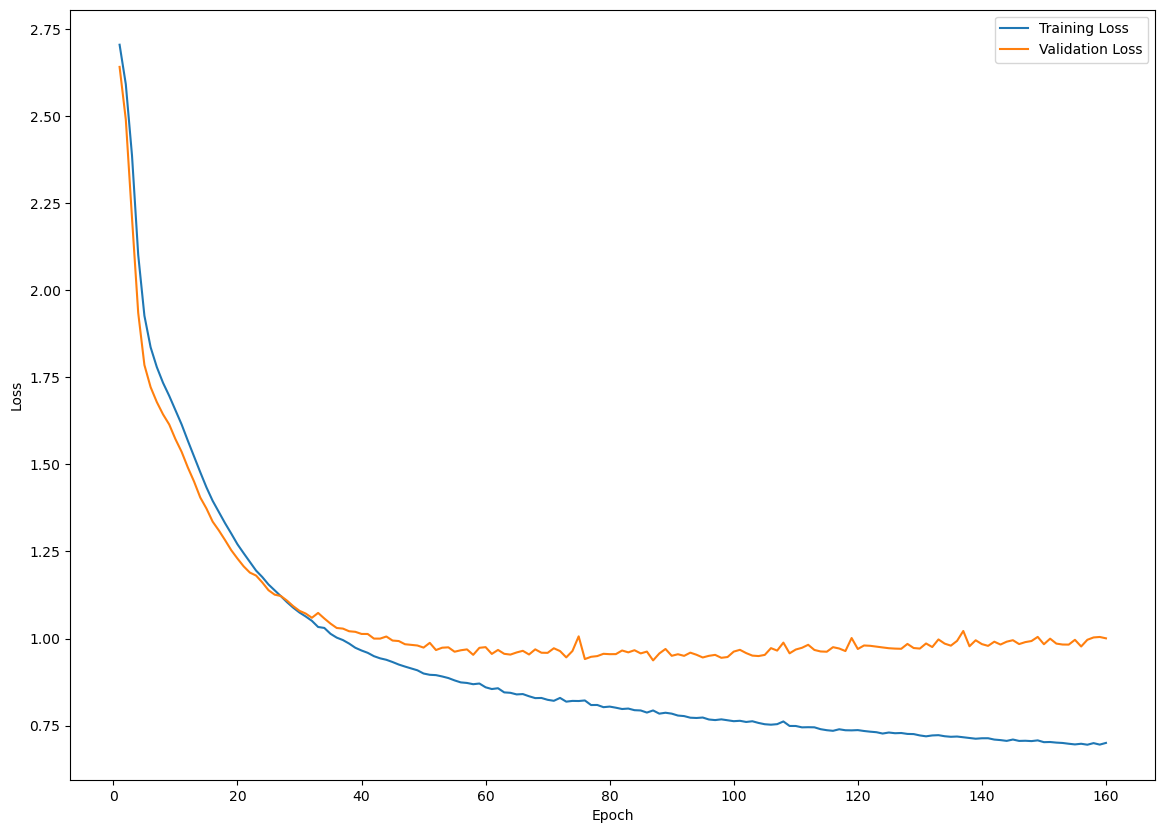

In [58]:
plt.figure(figsize=(14, 10))

epochs_range = range(1, epochs + 1)
train_loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs_range, train_loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [59]:
# np.argmin(val_loss) (68)

In [60]:
model.evaluate(X_test, y_test)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6381 - loss: 1.3870 


[1.387011170387268, 0.6380952596664429]